In [1]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

np.random.seed(42)

OUTPUT_DIR = "preprocessing_output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")

In [2]:

# Generate Synthetic Dataset

n = 1500

df = pd.DataFrame({
    "learner_id": range(1, n + 1),
    "prior_knowledge": np.random.randint(1, 11, n),
    "learning_pace": np.random.choice(
        ["Slow", "Moderate", "Fast"], n
    ),
    "simulation_type": np.random.choice(
        ["Science", "Engineering", "Medical", "General"], n
    ),
    "difficulty_level": np.random.randint(1, 6, n),
    "device_type": np.random.choice(
        ["Mobile", "Laptop", "Tablet"], n
    ),
    "interaction_frequency": np.random.poisson(18, n),
    "task_completion_rate": np.round(
        np.random.beta(5, 2, n), 2
    ),
    "avg_response_time_sec": np.round(
        np.random.gamma(3, 12, n), 2
    ),
    "hint_usage": np.random.poisson(3, n)
})

# Generate Preference Scores

text_score = (
    8 * (df["learning_pace"] == "Slow")
    + 4 * (df["prior_knowledge"] <= 4)
    + np.random.normal(0, 1, n)
)

visual_score = (
    8 * (df["simulation_type"] == "Science")
    + 4 * (df["simulation_type"] == "Medical")
    + np.random.normal(0, 1, n)
)

interactive_score = (
    8 * (df["learning_pace"] == "Fast")
    + 4 * (df["difficulty_level"] >= 4)
    + np.random.normal(0, 1, n)
)

# Assign Preferred Presentation

scores = np.column_stack([
    text_score, visual_score, interactive_score
])

variants = np.array(["Text", "Visual", "Interactive"])

df["preferred_presentation"] = variants[
    scores.argmax(axis=1)
]

# Save Dataset

df.to_csv(
    f"{OUTPUT_DIR}/synthetic_learner_data.csv",
    index=False
)

print("Dataset created:", df.shape)
print(df["preferred_presentation"].value_counts())
display(df.head())


Dataset created: (1500, 11)
preferred_presentation
Text           598
Interactive    557
Visual         345
Name: count, dtype: int64


,learner_id,prior_knowledge,learning_pace,simulation_type,difficulty_level,device_type,interaction_frequency,task_completion_rate,avg_response_time_sec,hint_usage,preferred_presentation
0,1,7,Slow,Medical,3,Tablet,16,0.88,57.67,3,Text
1,2,4,Moderate,General,1,Mobile,16,0.72,18.51,2,Text
2,3,8,Moderate,Science,2,Tablet,17,0.94,8.33,2,Visual
3,4,5,Fast,Science,5,Mobile,19,0.65,52.11,6,Interactive
4,5,7,Slow,General,1,Mobile,17,0.70,38.00,3,Text


In [3]:
# Generate stronger feature-based preference scores
text_score = (
    np.random.normal(5, 1.2, n)
    + (df["learning_pace"] == "Slow") * 2.2
    + (df["prior_knowledge"] <= 4) * 1.5
)

visual_score = (
    np.random.normal(5, 1.2, n)
    + (df["simulation_type"] == "Science") * 2.2
    + (df["simulation_type"] == "Medical") * 1.5
)

interactive_score = (
    np.random.normal(5, 1.2, n)
    + (df["learning_pace"] == "Fast") * 2.2
    + (df["difficulty_level"] >= 4) * 1.5
)

# Assign preferred presentation based on highest score
variants = np.array(["Text", "Visual", "Interactive"])

scores = np.column_stack([
    text_score,
    visual_score,
    interactive_score
])

df["preferred_presentation"] = variants[
    scores.argmax(axis=1)
]

# Generate interaction scores for dataset analysis
df["text_interaction_score"] = np.clip(
    np.round(text_score + np.random.normal(0, 1.5, n)),
    1, 10
)

df["visual_interaction_score"] = np.clip(
    np.round(visual_score + np.random.normal(0, 1.5, n)),
    1, 10
)

df["interactive_action_score"] = np.clip(
    np.round(interactive_score + np.random.normal(0, 1.5, n)),
    1, 10
)

# Save dataset
df.to_csv(
    f"{OUTPUT_DIR}/synthetic_learner_data.csv",
    index=False
)

print("Synthetic dataset created successfully!")
print("Shape:", df.shape)

print("\nPreferred Presentation Distribution:")
print(df["preferred_presentation"].value_counts())

display(df.head())

Synthetic dataset created successfully!
Shape: (1500, 14)

Preferred Presentation Distribution:
preferred_presentation
Text           576
Interactive    545
Visual         379
Name: count, dtype: int64


,learner_id,prior_knowledge,learning_pace,simulation_type,difficulty_level,device_type,interaction_frequency,task_completion_rate,avg_response_time_sec,hint_usage,preferred_presentation,text_interaction_score,visual_interaction_score,interactive_action_score
0,1,7,Slow,Medical,3,Tablet,16,0.88,57.67,3,Visual,7.0,9.0,5.0
1,2,4,Moderate,General,1,Mobile,16,0.72,18.51,2,Text,6.0,2.0,6.0
2,3,8,Moderate,Science,2,Tablet,17,0.94,8.33,2,Visual,7.0,6.0,7.0
3,4,5,Fast,Science,5,Mobile,19,0.65,52.11,6,Interactive,8.0,7.0,9.0
4,5,7,Slow,General,1,Mobile,17,0.70,38.00,3,Text,5.0,9.0,5.0


In [4]:
print("DATA TYPES")
print(df.dtypes)

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nSUMMARY STATISTICS")
display(df.describe())

df.isnull().sum().to_csv(
    f"{OUTPUT_DIR}/missing_values_before.csv"
)

DATA TYPES
learner_id                    int64
prior_knowledge               int32
learning_pace                   str
simulation_type                 str
difficulty_level              int32
device_type                     str
interaction_frequency         int32
task_completion_rate        float64
avg_response_time_sec       float64
hint_usage                    int32
preferred_presentation          str
text_interaction_score      float64
visual_interaction_score    float64
interactive_action_score    float64
dtype: object

MISSING VALUES
learner_id                  0
prior_knowledge             0
learning_pace               0
simulation_type             0
difficulty_level            0
device_type                 0
interaction_frequency       0
task_completion_rate        0
avg_response_time_sec       0
hint_usage                  0
preferred_presentation      0
text_interaction_score      0
visual_interaction_score    0
interactive_action_score    0
dtype: int64

DUPLICATE ROWS
0

SUM

,learner_id,prior_knowledge,difficulty_level,interaction_frequency,task_completion_rate,avg_response_time_sec,hint_usage,text_interaction_score,visual_interaction_score,interactive_action_score
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,750.500000,5.472000,3.020000,17.938000,0.714500,35.926580,3.007333,6.254000,5.957333,6.236000
std,433.157015,2.919172,1.410766,4.258589,0.157203,20.804346,1.692687,2.165012,2.061960,2.191386
min,1.000000,1.000000,1.000000,4.000000,0.200000,1.590000,0.000000,1.000000,1.000000,1.000000
25%,375.750000,3.000000,2.000000,15.000000,0.620000,20.875000,2.000000,5.000000,5.000000,5.000000
50%,750.500000,5.000000,3.000000,18.000000,0.730000,31.925000,3.000000,6.000000,6.000000,6.000000
75%,1125.250000,8.000000,4.000000,21.000000,0.830000,46.507500,4.000000,8.000000,7.000000,8.000000
max,1500.000000,10.000000,5.000000,33.000000,0.990000,150.970000,11.000000,10.000000,10.000000,10.000000


In [5]:
feature_cols = [
    "prior_knowledge",
    "learning_pace",
    "difficulty_level",
    "device_type",
    "interaction_frequency",
    "task_completion_rate",
    "avg_response_time_sec",
    "hint_usage",
    "text_interaction_score",
    "visual_interaction_score",
    "interactive_action_score"
]

missing_idx = df.sample(
    frac=0.02,
    random_state=42
).index

for col in feature_cols:
    df.loc[missing_idx, col] = np.nan

print("Missing values introduced:")
print(df.isnull().sum())

Missing values introduced:
learner_id                   0
prior_knowledge             30
learning_pace               30
simulation_type              0
difficulty_level            30
device_type                 30
interaction_frequency       30
task_completion_rate        30
avg_response_time_sec       30
hint_usage                  30
preferred_presentation       0
text_interaction_score      30
visual_interaction_score    30
interactive_action_score    30
dtype: int64


In [6]:
rows_before = len(df)

df = df.drop_duplicates().copy()

# Remove unwanted spaces from categorical values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Remove rows where the target is missing
df = df.dropna(
    subset=["preferred_presentation"]
).copy()

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", len(df))

df.to_csv(
    f"{OUTPUT_DIR}/cleaned_data.csv",
    index=False
)

Rows before cleaning: 1500
Rows after cleaning: 1500


C:\Users\gubba\AppData\Local\Temp\ipykernel_37016\34634269.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


In [7]:
print("PREFERENCE COUNTS")
print(df["preferred_presentation"].value_counts())

print("\nMISSING VALUE PERCENTAGE")
print((df.isnull().mean() * 100).round(2))

PREFERENCE COUNTS
preferred_presentation
Text           576
Interactive    545
Visual         379
Name: count, dtype: int64

MISSING VALUE PERCENTAGE
learner_id                  0.0
prior_knowledge             2.0
learning_pace               2.0
simulation_type             0.0
difficulty_level            2.0
device_type                 2.0
interaction_frequency       2.0
task_completion_rate        2.0
avg_response_time_sec       2.0
hint_usage                  2.0
preferred_presentation      0.0
text_interaction_score      2.0
visual_interaction_score    2.0
interactive_action_score    2.0
dtype: float64


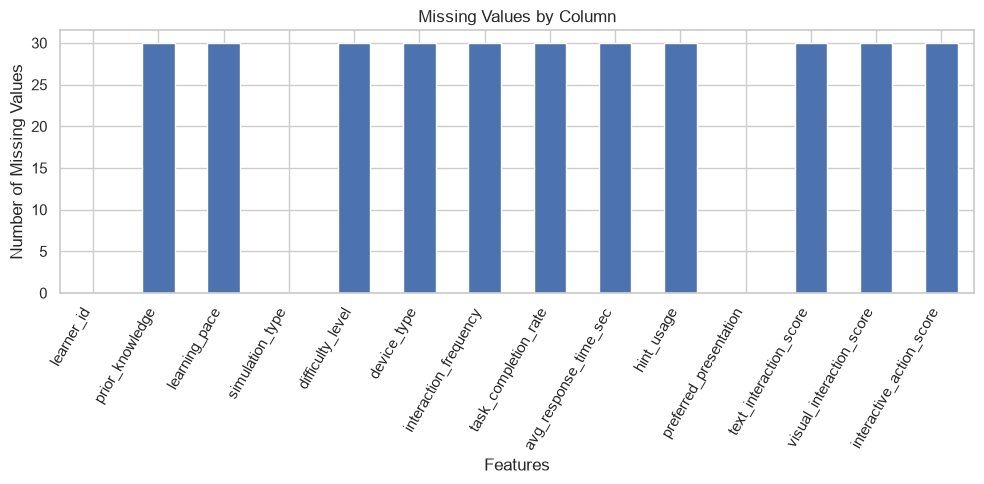

In [8]:
plt.figure(figsize=(10, 5))

df.isnull().sum().plot(kind="bar")

plt.title("Missing Values by Column")
plt.xlabel("Features")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()

plt.savefig(f"{OUTPUT_DIR}/missing_values.png")
plt.show()

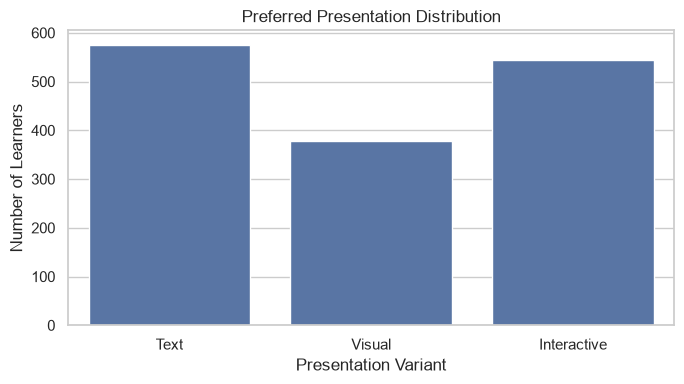

In [9]:
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="preferred_presentation",
    order=["Text", "Visual", "Interactive"]
)

plt.title("Preferred Presentation Distribution")
plt.xlabel("Presentation Variant")
plt.ylabel("Number of Learners")
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/presentation_distribution.png"
)
plt.show()

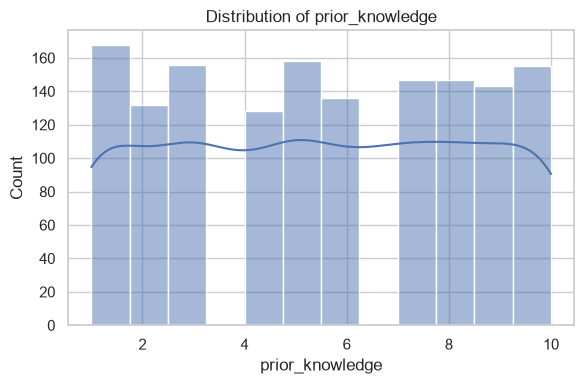

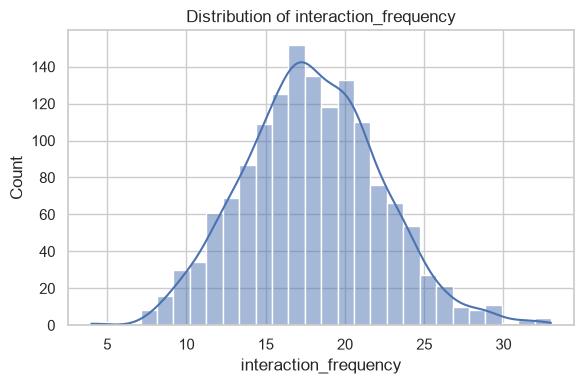

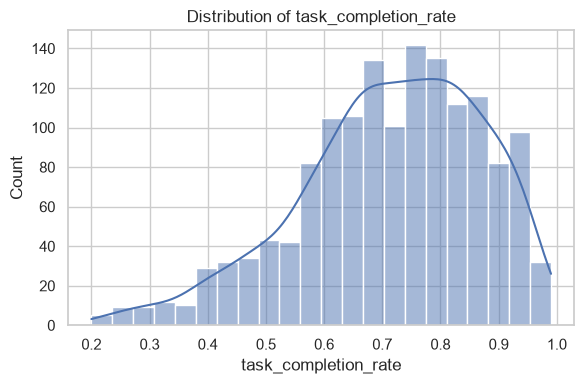

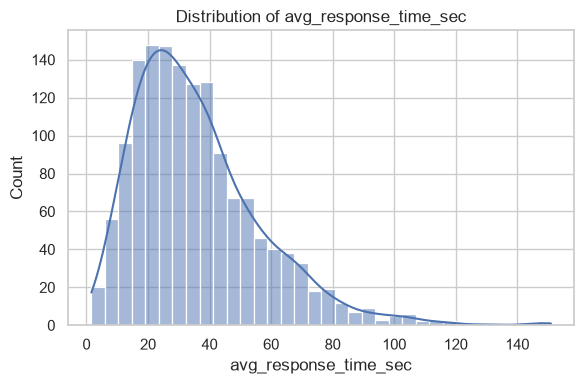

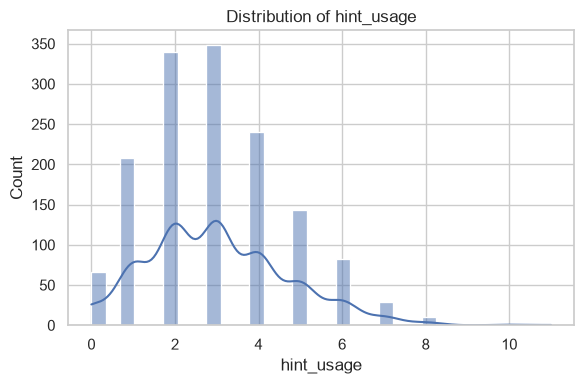

In [10]:
numeric_columns = [
    "prior_knowledge",
    "interaction_frequency",
    "task_completion_rate",
    "avg_response_time_sec",
    "hint_usage"
]

for col in numeric_columns:
    plt.figure(figsize=(6, 4))

    sns.histplot(
        data=df,
        x=col,
        kde=True
    )

    plt.title(f"Distribution of {col}")
    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/distribution_{col}.png"
    )

    plt.show()
    plt.close()

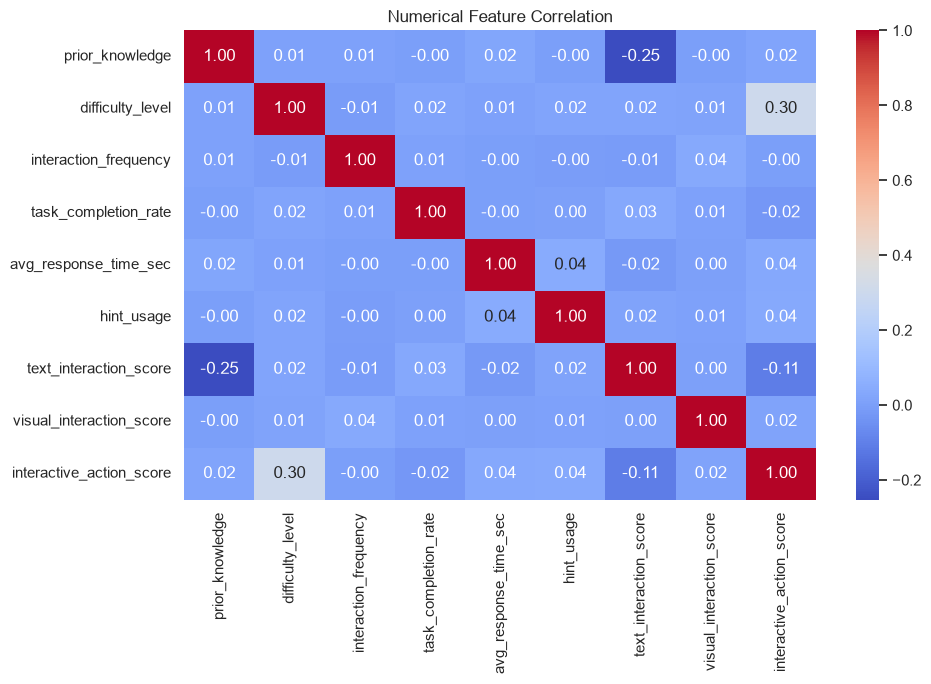

In [11]:
numeric_cols = df.select_dtypes(
    include=np.number
).columns.drop("learner_id", errors="ignore")

plt.figure(figsize=(10, 7))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Numerical Feature Correlation")
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/correlation_heatmap.png"
)

plt.show()

In [12]:
TARGET = "preferred_presentation"

X = df.drop(
    columns=["learner_id", TARGET]
)

y = df[TARGET].copy()

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# Fill missing numerical values with the median
num_imputer = SimpleImputer(strategy="median")

X_numeric = pd.DataFrame(
    num_imputer.fit_transform(X[numeric_features]),
    columns=numeric_features,
    index=X.index
)

# Fill missing categorical values with the most common value
cat_imputer = SimpleImputer(strategy="most_frequent")

X_categorical = pd.DataFrame(
    cat_imputer.fit_transform(X[categorical_features]),
    columns=categorical_features,
    index=X.index
)

# Convert categorical values into numerical columns
encoder = OneHotEncoder(handle_unknown="ignore")

encoded_array = encoder.fit_transform(
    X_categorical
).toarray()

encoded_names = encoder.get_feature_names_out(
    categorical_features
)

X_encoded = pd.DataFrame(
    encoded_array,
    columns=encoded_names,
    index=X.index
)

# Standardize numerical features
scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X_numeric),
    columns=numeric_features,
    index=X.index
)

# Combine numerical and categorical features
X_processed = pd.concat(
    [X_scaled, X_encoded],
    axis=1
)

# Save processed data
X_processed.to_csv(
    f"{OUTPUT_DIR}/processed_features.csv",
    index=False
)

y.to_frame().to_csv(
    f"{OUTPUT_DIR}/preference_target.csv",
    index=False
)

X_processed.to_csv(
    f"{OUTPUT_DIR}/clustering_features.csv",
    index=False
)

print("\nPREFERENCE vs LEARNING PACE")
print(pd.crosstab(df["learning_pace"], df["preferred_presentation"],
                  normalize="index").round(2))

print("\nPREFERENCE vs SIMULATION TYPE")
print(pd.crosstab(df["simulation_type"], df["preferred_presentation"],
                  normalize="index").round(2))

print("\nPREFERENCE vs DIFFICULTY LEVEL")
print(pd.crosstab(df["difficulty_level"], df["preferred_presentation"],
                  normalize="index").round(2))

print("PREPROCESSING COMPLETE")
print("Processed feature shape:", X_processed.shape)
print("Remaining missing values:", X_processed.isnull().sum().sum())

print("\nTARGET DISTRIBUTION")
print(y.value_counts())


PREFERENCE vs LEARNING PACE
preferred_presentation  Interactive  Text  Visual
learning_pace                                    
Fast                           0.75  0.09    0.16
Moderate                       0.27  0.31    0.42
Slow                           0.09  0.74    0.16

PREFERENCE vs SIMULATION TYPE
preferred_presentation  Interactive  Text  Visual
simulation_type                                  
Engineering                    0.46  0.45    0.09
General                        0.41  0.49    0.10
Medical                        0.34  0.34    0.32
Science                        0.26  0.27    0.47

PREFERENCE vs DIFFICULTY LEVEL
preferred_presentation  Interactive  Text  Visual
difficulty_level                                 
1.0                            0.29  0.42    0.29
2.0                            0.28  0.41    0.31
3.0                            0.25  0.45    0.30
4.0                            0.49  0.33    0.19
5.0                            0.51  0.31    0.18
PREPROCE

In [13]:
# Import Libraries
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score, classification_report

# Separate Features and Target
X = df.drop(columns=[
    "learner_id",
    "preferred_presentation",
    "text_interaction_score",
    "visual_interaction_score",
    "interactive_action_score"
], errors="ignore")

y = df["preferred_presentation"]

# Identify Features
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

# Numerical Preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical Preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine Preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Models
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_split=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        random_state=42
    ),

    "Logistic Regression": LogisticRegression(
        C=1.0,
        max_iter=2000
    )
}

# Train and Evaluate
for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    print("\n", name)
    print("Test Accuracy:", round(accuracy * 100, 2), "%")
    print("-" * 50)


 Decision Tree
Test Accuracy: 72.67 %
--------------------------------------------------

 Random Forest
Test Accuracy: 70.0 %
--------------------------------------------------

 Logistic Regression
Test Accuracy: 71.33 %
--------------------------------------------------


In [14]:

# Import Libraries
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Define Models and Parameters
models = {
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {
            "clf__max_depth": [5, 10, None],
            "clf__min_samples_split": [2, 5]
        }
    ),

    "Random Forest": (
        RandomForestClassifier(random_state=42),
        {
            "clf__n_estimators": [100, 200],
            "clf__max_depth": [5, 10, None]
        }
    ),

    "Logistic Regression": (
        LogisticRegression(max_iter=1000),
        {
            "clf__C": [0.1, 1, 10]
        }
    )
}

# Tune and Evaluate Models
for name, (model, params) in models.items():

    pipeline = Pipeline([
        ("encode", encoder),
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("scale", StandardScaler(with_mean=False)),
        ("clf", model)
    ])

    grid = GridSearchCV(
        pipeline,
        params,
        cv=3,
        scoring="accuracy"
    )

    grid.fit(X_train, y_train)

    y_pred = grid.predict(X_test)

    print("\n", name)
    print("Best Parameters:", grid.best_params_)
    print("Best CV Accuracy:", round(grid.best_score_ * 100, 2), "%")
    print("Test Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")



 Decision Tree
Best Parameters: {'clf__max_depth': 5, 'clf__min_samples_split': 2}
Best CV Accuracy: 64.67 %
Test Accuracy: 71.67 %

 Random Forest
Best Parameters: {'clf__max_depth': None, 'clf__n_estimators': 200}
Best CV Accuracy: 66.67 %
Test Accuracy: 72.0 %

 Logistic Regression
Best Parameters: {'clf__C': 0.1}
Best CV Accuracy: 60.0 %
Test Accuracy: 64.67 %



 Decision Tree
[[64 31 14]
 [30 66 19]
 [19 26 31]]


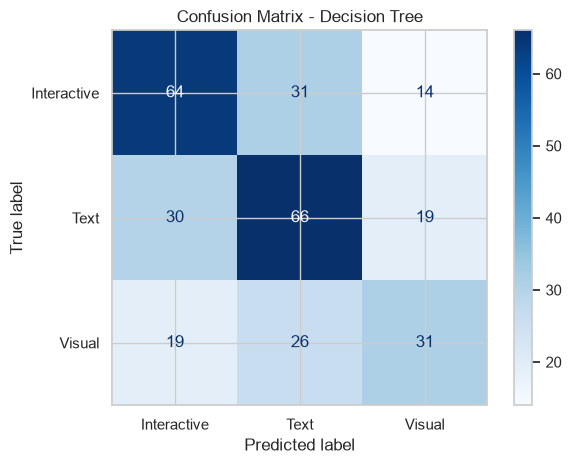


 Random Forest
[[82 17 10]
 [16 89 10]
 [20 24 32]]


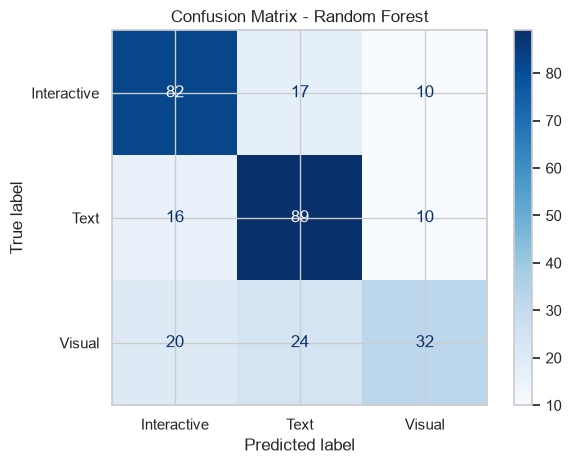


 Logistic Regression
[[86 15  8]
 [15 93  7]
 [20 21 35]]


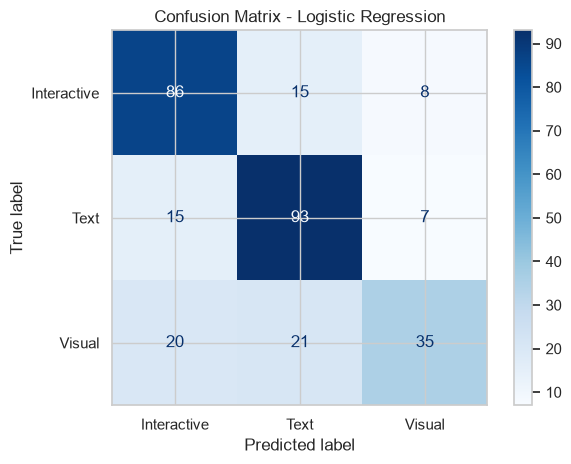

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt

for name, model_info in models.items():

    # Extract classifier from (model, parameter_grid)
    model = model_info[0] if isinstance(model_info, tuple) else model_info

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=pipeline.classes_
    )

    print("\n", name)
    print(cm)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=pipeline.classes_
    )

    disp.plot(cmap="Blues")
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

In [ ]:
from sklearn.metrics import classification_report

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    print("\n", name)
    print("=" * 50)

    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))


 Decision Tree
              precision    recall  f1-score   support

 Interactive       0.43      0.38      0.40       112
        Text       0.37      0.62      0.47       100
      Visual       0.27      0.11      0.16        88

    accuracy                           0.38       300
   macro avg       0.36      0.37      0.34       300
weighted avg       0.37      0.38      0.35       300


 Random Forest
              precision    recall  f1-score   support

 Interactive       0.46      0.56      0.51       112
        Text       0.37      0.40      0.38       100
      Visual       0.42      0.26      0.32        88

    accuracy                           0.42       300
   macro avg       0.42      0.41      0.40       300
weighted avg       0.42      0.42      0.41       300


 Logistic Regression
              precision    recall  f1-score   support

 Interactive       0.39      0.46      0.43       112
        Text       0.38      0.43      0.40       100
      Visual       0.

PREFERENCE vs LEARNING PACE
preferred_presentation  Interactive   Text  Visual
learning_pace                                     
Fast                          74.95   9.07   15.98
Moderate                      27.24  30.54   42.22
Slow                           9.33  74.24   16.43


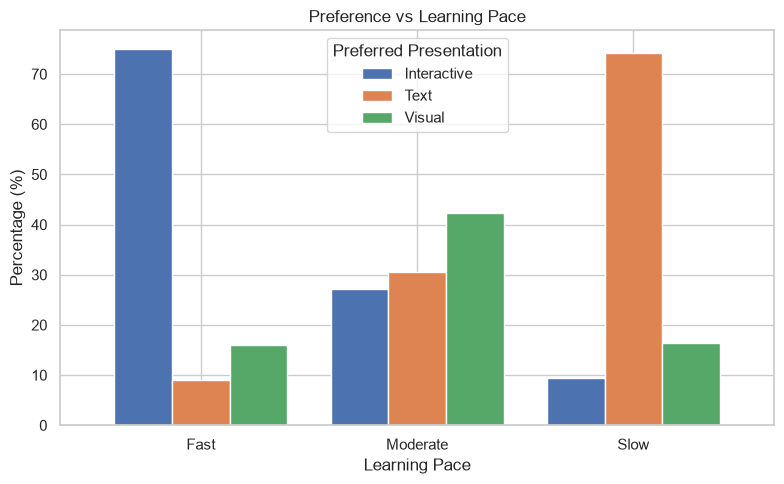

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preference vs Learning Pace
pace_preference = pd.crosstab(
    df["learning_pace"],
    df["preferred_presentation"],
    normalize="index"
) * 100

print("PREFERENCE vs LEARNING PACE")
print(pace_preference.round(2))

# Plot
pace_preference.plot(
    kind="bar",
    figsize=(8, 5),
    width=0.8
)

plt.title("Preference vs Learning Pace")
plt.xlabel("Learning Pace")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Preferred Presentation")
plt.tight_layout()
plt.show()

PREFERENCE vs SIMULATION TYPE
preferred_presentation  Interactive   Text  Visual
simulation_type                                   
Engineering                   45.64  45.35    9.01
General                       41.49  48.94    9.57
Medical                       33.69  33.96   32.35
Science                       26.16  26.89   46.94


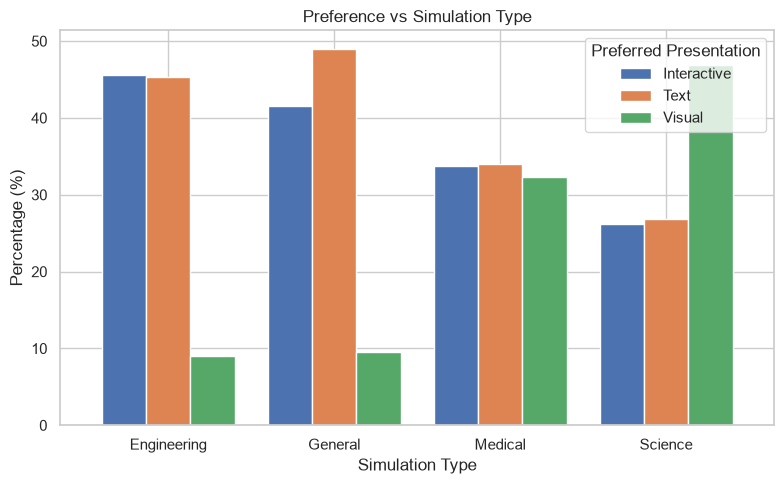

In [18]:
# Preference vs Simulation Type
simulation_preference = pd.crosstab(
    df["simulation_type"],
    df["preferred_presentation"],
    normalize="index"
) * 100

print("PREFERENCE vs SIMULATION TYPE")
print(simulation_preference.round(2))

# Plot
simulation_preference.plot(
    kind="bar",
    figsize=(8, 5),
    width=0.8
)

plt.title("Preference vs Simulation Type")
plt.xlabel("Simulation Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Preferred Presentation")
plt.tight_layout()
plt.show()

PREFERENCE vs DIFFICULTY LEVEL
preferred_presentation  Interactive   Text  Visual
difficulty_level                                  
1.0                           28.77  42.46   28.77
2.0                           27.78  41.32   30.90
3.0                           24.59  45.25   30.16
4.0                           48.80  32.65   18.56
5.0                           51.16  30.56   18.27


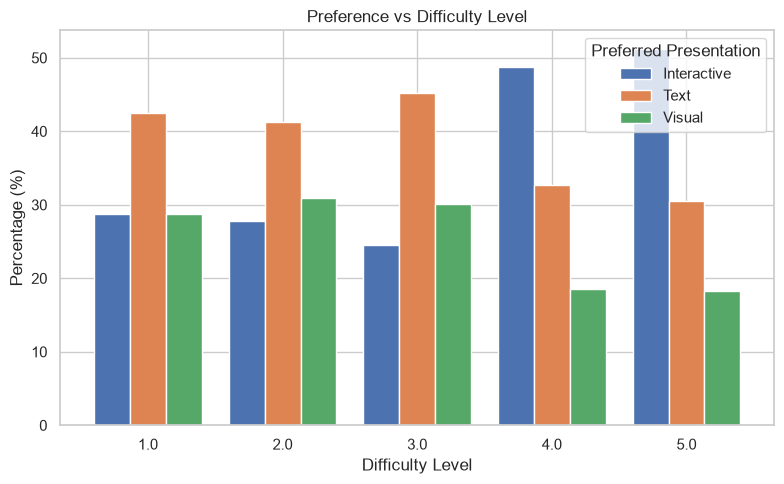

: 

In [ ]:
# Preference vs Difficulty Level
difficulty_preference = pd.crosstab(
    df["difficulty_level"],
    df["preferred_presentation"],
    normalize="index"
) * 100

print("PREFERENCE vs DIFFICULTY LEVEL")
print(difficulty_preference.round(2))

# Plot
difficulty_preference.plot(
    kind="bar",
    figsize=(8, 5),
    width=0.8
)

plt.title("Preference vs Difficulty Level")
plt.xlabel("Difficulty Level")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Preferred Presentation")
plt.tight_layout()
plt.show()